# Практичне заняття 8
## Структурний кластерний та семантичний аналіз графа Wikidata

**Виконав:** Єрмолович Захар Максимович  
**Варіант:** 12  
**Домен:** Географія та адміністративний устрій  
**Вхідні дані:** знімок графа практичної 7, отриманий 26.10.2026

Мета — знайти структурні спільноти, дослідити роль хабів і стійкість
мережі, пояснити семантичні шляхи та оцінити гіпотезу про відсутній P131.
Використовується той самий географічний граф із 2389 сутностей та 4402
ребер. Вузли мають типи City, Country, AdministrativeTerritory; країна Q183
утворює спільне ядро.

Ноутбук містить код і стиснений знімок даних. Запускайте комірки згори
вниз; результати записуються у `outputs/`. Обчислювальні функції збігаються
зі скриптом `structural_analysis.py`. Параметри зафіксовано: seed=12,
resolution=1, 500 випадкових випробувань, довжина шляхів для Link Prediction
не перевищує 3 ребер.

In [1]:
import importlib.util
import subprocess
import sys

packages = {
    "networkx": "networkx==3.7", "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.4", "scipy": "scipy==1.18.1", "pandas": "pandas==3.0.1",
}
missing = [package for name, package in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

In [2]:
from __future__ import annotations
import hashlib
import json
import math
import platform
import textwrap
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy
from matplotlib.figure import Figure

import base64
import gzip
from IPython.display import display, Markdown

INPUT_SHA256 = "5ec861b5967eb325c6dfae0ce7a36993b95d44e8da5a34e86f539d990616561e"
COUNTRY = "Q183"

@dataclass(frozen=True)
class AnalysisConfig:
    seed: int = 12
    resolution: float = 1.0
    attack_steps: int = 5
    random_trials: int = 500
    path_cutoff: int = 3

DEFAULT_CONFIG = AnalysisConfig()

@dataclass
class AnalysisResult:
    graph: nx.MultiDiGraph
    undirected: nx.Graph
    communities: list[set[str]]
    scores: pd.DataFrame
    tables: dict[str, pd.DataFrame]
    metrics: dict[str, Any]
    details: dict[str, Any]
    main_ego: nx.Graph
    local_ego: nx.Graph

def write_json(path: Path, value: Any) -> None:
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
        newline="\n",
    )


def library_versions() -> dict[str, str]:
    return {
        "python": platform.python_version(),
        "networkx": nx.__version__,
        "matplotlib": matplotlib.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
    }


def load_graph(payload: bytes, *, minimum_nodes: int = 1500) -> nx.MultiDiGraph:
    graph = nx.node_link_graph(json.loads(payload), edges="edges")
    if not graph.is_directed() or not graph.is_multigraph():
        raise ValueError("The source must be a directed multigraph")
    if len(graph) < minimum_nodes or not nx.is_weakly_connected(graph):
        raise ValueError("The source is too small or weakly disconnected")
    if nx.number_of_selfloops(graph) or list(nx.isolates(graph)):
        raise ValueError("The source contains self-loops or isolated nodes")
    for node, data in graph.nodes(data=True):
        if (
            not isinstance(node, str)
            or not node.startswith("Q")
            or not node[1:].isdigit()
        ):
            raise ValueError("Literal nodes are not allowed")
        if data.get("type") not in {"City", "Country", "AdministrativeTerritory"}:
            raise ValueError(f"Missing or unsupported entity type: {node}")
        if not data.get("label"):
            raise ValueError(f"Missing label: {node}")
    for _, _, data in graph.edges(data=True):
        if data.get("property") not in {"P17", "P131"}:
            raise ValueError("Unexpected geographic predicate")
    return graph


def undirected_projection(graph: nx.Graph) -> nx.Graph:
    projected = nx.Graph()
    projected.add_nodes_from((node, dict(graph.nodes[node])) for node in sorted(graph))
    projected.add_edges_from(sorted({tuple(sorted((u, v))) for u, v in graph.edges()}))
    return projected


def normalized_mutual_information(first: list[Any], second: list[Any]) -> float:
    if len(first) != len(second) or not first:
        raise ValueError("Partitions must have equal nonzero lengths")
    total = len(first)
    left, right = Counter(first), Counter(second)
    information = sum(
        count / total * math.log(count * total / (left[a] * right[b]))
        for (a, b), count in Counter(zip(first, second, strict=True)).items()
    )

    def entropy(counts: Counter[Any]) -> float:
        return -sum(c / total * math.log(c / total) for c in counts.values())

    denominator = entropy(left) + entropy(right)
    return (
        1.0 if denominator == 0 else min(1.0, max(0.0, 2 * information / denominator))
    )


def administrative_index(
    graph: nx.MultiDiGraph,
) -> tuple[dict[str, set[str]], dict[str, set[str]]]:
    parents: dict[str, set[str]] = defaultdict(set)
    members: dict[str, set[str]] = defaultdict(set)
    for source, target, data in graph.edges(data=True):
        if data["property"] == "P131":
            parents[source].add(target)
            members[target].add(source)
    return dict(parents), dict(members)


def community_analysis(
    graph: nx.MultiDiGraph,
    undirected: nx.Graph,
    config: AnalysisConfig = DEFAULT_CONFIG,
) -> tuple[list[set[str]], pd.DataFrame, dict[str, pd.DataFrame], dict[str, Any]]:
    communities = nx.community.louvain_communities(
        undirected,
        weight=None,
        resolution=config.resolution,
        seed=config.seed,
    )
    communities.sort(key=lambda nodes: (-len(nodes), min(nodes)))
    community_of = {
        node: index for index, nodes in enumerate(communities) for node in nodes
    }
    pagerank = nx.pagerank(
        undirected, alpha=0.85, weight=None, tol=1e-12, max_iter=1000
    )
    degree = nx.degree_centrality(undirected)
    scores = pd.DataFrame(
        [
            {
                "qid": node,
                "label": graph.nodes[node]["label"],
                "type": graph.nodes[node]["type"],
                "degree": undirected.degree(node),
                "degree_centrality": degree[node],
                "pagerank": pagerank[node],
                "community": community_of[node],
            }
            for node in sorted(undirected)
        ]
    ).set_index("qid")
    bridges = {frozenset(edge) for edge in nx.bridges(undirected)}
    parents, _ = administrative_index(graph)
    primary_admin = {city: min(admins) for city, admins in parents.items()}
    rows, centralities, compositions, admin_groups = [], [], [], []
    for index, nodes in enumerate(communities):
        subgraph = undirected_projection(undirected.subgraph(nodes))
        internal_degree = nx.degree_centrality(subgraph)
        internal_between = nx.betweenness_centrality(
            subgraph, weight=None, normalized=True
        )
        degree_order = sorted(nodes, key=lambda node: (-internal_degree[node], node))
        between_order = sorted(nodes, key=lambda node: (-internal_between[node], node))
        boundary = sum(1 for _ in nx.edge_boundary(undirected, nodes))
        counts = Counter(graph.nodes[node]["type"] for node in nodes)
        city_groups = Counter(
            primary_admin[node] for node in sorted(nodes) if node in primary_admin
        )
        dominant_admin, dominant_size = (
            min(city_groups.items(), key=lambda item: (-item[1], item[0]))
            if city_groups
            else ("", 0)
        )
        rows.append(
            {
                "community": index,
                "nodes": len(nodes),
                "edges": subgraph.number_of_edges(),
                "density": nx.density(subgraph),
                "components": nx.number_connected_components(subgraph),
                "boundary_edges": boundary,
                "boundary_fraction": boundary
                / (2 * subgraph.number_of_edges() + boundary),
                "degree_hub": degree_order[0],
                "degree_hub_label": graph.nodes[degree_order[0]]["label"],
                "betweenness_hub": between_order[0],
                "betweenness_hub_label": graph.nodes[between_order[0]]["label"],
                "dominant_primary_admin": dominant_admin,
                "dominant_primary_admin_label": graph.nodes[dominant_admin]["label"]
                if dominant_admin
                else "",
                "dominant_admin_city_count": dominant_size,
            }
        )
        for node_type, count in sorted(counts.items()):
            compositions.append(
                {
                    "community": index,
                    "type": node_type,
                    "nodes": count,
                    "fraction": count / len(nodes),
                }
            )
        for admin, count in sorted(city_groups.items()):
            admin_groups.append(
                {
                    "community": index,
                    "primary_admin": admin,
                    "admin_label": graph.nodes[admin]["label"],
                    "cities": count,
                }
            )
        selected = sorted(set(degree_order[:3]) | set(between_order[:3]))
        for node in selected:
            centralities.append(
                {
                    "community": index,
                    "qid": node,
                    "label": graph.nodes[node]["label"],
                    "type": graph.nodes[node]["type"],
                    "internal_degree": subgraph.degree(node),
                    "degree_centrality": internal_degree[node],
                    "betweenness": internal_between[node],
                }
            )
    cross_edges, pairs = [], Counter()
    for u, v in sorted(undirected.edges()):
        first, second = community_of[u], community_of[v]
        if first != second:
            pairs[tuple(sorted((first, second)))] += 1
            cross_edges.append(
                {
                    "source": u,
                    "source_label": graph.nodes[u]["label"],
                    "source_community": first,
                    "target": v,
                    "target_label": graph.nodes[v]["label"],
                    "target_community": second,
                    "is_graph_bridge": frozenset((u, v)) in bridges,
                }
            )
    anomalies = [
        {
            "city": city,
            "city_label": graph.nodes[city]["label"],
            "admin_count": len(admins),
            "admin_qids": "; ".join(sorted(admins)),
            "admin_labels": "; ".join(
                graph.nodes[admin]["label"] for admin in sorted(admins)
            ),
        }
        for city, admins in sorted(parents.items())
        if len(admins) > 1
    ]
    composition = pd.DataFrame(compositions)
    purity = composition.groupby("community").nodes.max().sum() / len(undirected)
    cities = sorted(primary_admin)
    types = [graph.nodes[node]["type"] for node in sorted(undirected)]
    tables = {
        "community_summary": pd.DataFrame(rows),
        "community_hubs": pd.DataFrame(centralities),
        "community_composition": composition,
        "community_admin_groups": pd.DataFrame(admin_groups),
        "intercommunity_edges": pd.DataFrame(cross_edges),
        "intercommunity_pairs": pd.DataFrame(
            [
                {
                    "first_community": pair[0],
                    "second_community": pair[1],
                    "edges": count,
                }
                for pair, count in pairs.most_common()
            ]
        ),
        "graph_bridges": pd.DataFrame(
            [
                {"source": u, "target": v}
                for u, v in sorted(tuple(sorted(edge)) for edge in bridges)
            ],
            columns=["source", "target"],
        ),
        "multiple_admin_cities": pd.DataFrame(anomalies).sort_values(
            ["admin_count", "city"],
            ascending=[False, True],
        )
        if anomalies
        else pd.DataFrame(
            columns=["city", "city_label", "admin_count", "admin_qids", "admin_labels"]
        ),
    }
    metrics = {
        "count": len(communities),
        "resolution": config.resolution,
        "modularity": nx.community.modularity(
            undirected, communities, weight=None, resolution=config.resolution
        ),
        "type_nmi": normalized_mutual_information(
            types, [community_of[n] for n in sorted(undirected)]
        ),
        "type_purity": float(purity),
        "majority_type_baseline": max(Counter(types).values()) / len(types),
        "city_primary_admin_nmi": normalized_mutual_information(
            [primary_admin[city] for city in cities],
            [community_of[city] for city in cities],
        ),
        "sampling_country_groups": 1,
        "intercommunity_edges": len(cross_edges),
        "intercommunity_predicates": dict(
            Counter(
                data["property"]
                for u, v, data in graph.edges(data=True)
                if community_of[u] != community_of[v]
            )
        ),
        "graph_bridges": len(bridges),
        "articulation_points": sorted(nx.articulation_points(undirected)),
        "multiple_admin_cities": len(anomalies),
    }
    return communities, scores, tables, metrics


def component_statistics(graph: nx.Graph, initial_size: int) -> dict[str, float | int]:
    sizes = [len(nodes) for nodes in nx.connected_components(graph)]
    largest = max(sizes, default=0)
    return {
        "remaining_nodes": len(graph),
        "components": len(sizes),
        "largest_component": largest,
        "largest_fraction_initial": largest / initial_size,
        "largest_fraction_remaining": largest / len(graph) if graph else 0.0,
        "isolates": len(list(nx.isolates(graph))),
    }


def deletion_trace(graph: nx.Graph, order: list[str]) -> pd.DataFrame:
    if len(set(order)) != len(order) or any(node not in graph for node in order):
        raise ValueError("Removal order must contain distinct existing nodes")
    working = graph.copy()
    rows = [
        {
            "step": 0,
            "removed_qid": "",
            "removed_label": "",
            "removed_type": "",
            **component_statistics(working, len(graph)),
        }
    ]
    for step, node in enumerate(order, start=1):
        data = graph.nodes[node]
        working.remove_node(node)
        rows.append(
            {
                "step": step,
                "removed_qid": node,
                "removed_label": data.get("label", node),
                "removed_type": data.get("type", ""),
                **component_statistics(working, len(graph)),
            }
        )
    return pd.DataFrame(rows)


def resilience_analysis(
    graph: nx.Graph,
    scores: pd.DataFrame,
    config: AnalysisConfig = DEFAULT_CONFIG,
) -> tuple[dict[str, pd.DataFrame], dict[str, Any]]:
    if config.attack_steps >= len(graph) or config.random_trials < 1:
        raise ValueError("Choose fewer removals than nodes and a positive trial count")
    ranking = sorted(
        scores.index, key=lambda node: (-scores.at[node, "pagerank"], node)
    )
    order = ranking[: config.attack_steps]
    targeted = deletion_trace(graph, order)
    targeted["initial_pagerank"] = [0.0] + [
        float(scores.at[node, "pagerank"]) for node in order
    ]
    rng = np.random.default_rng(config.seed)
    nodes = np.array(sorted(graph), dtype=object)
    trials = []
    for trial in range(config.random_trials):
        random_order = rng.choice(
            nodes, size=config.attack_steps, replace=False
        ).tolist()
        trace = deletion_trace(graph, random_order)
        trace.insert(0, "trial", trial)
        trials.append(trace)
    random_traces = pd.concat(trials, ignore_index=True)
    random_summary = (
        random_traces.groupby("step")
        .agg(
            components_mean=("components", "mean"),
            components_p025=("components", lambda values: values.quantile(0.025)),
            components_p975=("components", lambda values: values.quantile(0.975)),
            largest_mean=("largest_component", "mean"),
            largest_p025=("largest_component", lambda values: values.quantile(0.025)),
            largest_p975=("largest_component", lambda values: values.quantile(0.975)),
        )
        .reset_index()
    )
    final_random = random_traces[random_traces.step == config.attack_steps]
    final_target = targeted.iloc[-1]
    metrics = {
        "attack_ranking": "PageRank on the initial undirected graph; no recomputation",
        "targeted_order": order,
        "random_trials": config.random_trials,
        "targeted_final_components": int(final_target.components),
        "targeted_final_largest": int(final_target.largest_component),
        "random_final_components_mean": float(final_random.components.mean()),
        "random_final_largest_mean": float(final_random.largest_component.mean()),
        "random_largest_le_targeted_fraction": float(
            (final_random.largest_component <= final_target.largest_component).mean()
        ),
        "random_includes_main_hub_trials": int(
            random_traces.loc[random_traces.removed_qid == order[0], "trial"].nunique()
        ),
        "main_hub_is_universal": graph.degree(order[0]) == len(graph) - 1,
        "random_main_hub_hit_probability": config.attack_steps / len(graph),
        "expected_random_main_hub_hits": config.random_trials
        * config.attack_steps
        / len(graph),
        "probability_no_main_hub_hit_in_trials": (1 - config.attack_steps / len(graph))
        ** config.random_trials,
    }
    return {
        "targeted_attack": targeted,
        "random_attack_trials": random_traces,
        "random_attack_summary": random_summary,
        "initial_top5_pagerank": scores.loc[order].reset_index(),
    }, metrics


def semantic_steps(graph: nx.MultiDiGraph, path: list[str]) -> pd.DataFrame:
    rows = []
    for step, (u, v) in enumerate(zip(path, path[1:], strict=False), start=1):
        found = False
        for source, target, direction in ((u, v, "along"), (v, u, "against")):
            for key, data in sorted(
                graph.get_edge_data(source, target, default={}).items()
            ):
                rows.append(
                    {
                        "step": step,
                        "traversal_from": u,
                        "traversal_to": v,
                        "rdf_source": source,
                        "rdf_source_label": graph.nodes[source]["label"],
                        "rdf_target": target,
                        "rdf_target_label": graph.nodes[target]["label"],
                        "property": data["property"],
                        "relation": data.get("relation", ""),
                        "property_uri": data.get("property_uri", ""),
                        "edge_key": str(key),
                        "traversal_direction": direction,
                    }
                )
                found = True
        if not found:
            raise ValueError(f"Path step has no original RDF edge: {u}, {v}")
    return pd.DataFrame(rows)


def path_text(graph: nx.MultiDiGraph, path: list[str]) -> str:
    steps = semantic_steps(graph, path)
    text = f"{graph.nodes[path[0]]['label']} ({path[0]})"
    for index, node in enumerate(path[1:], start=1):
        links = steps[steps.step == index]
        predicates = ", ".join(sorted(set(links.property)))
        direction = set(links.traversal_direction)
        connector = (
            f" —{predicates}→ " if direction == {"along"} else f" ←{predicates}— "
        )
        if len(direction) > 1:
            connector = f" ←{predicates}→ "
        text += connector + f"{graph.nodes[node]['label']} ({node})"
    return text


def semantic_analysis(
    graph: nx.MultiDiGraph,
    undirected: nx.Graph,
    scores: pd.DataFrame,
) -> tuple[dict[str, pd.DataFrame], dict[str, Any], dict[str, Any], nx.Graph, nx.Graph]:
    parents, _ = administrative_index(graph)
    cities = sorted(parents, key=lambda node: (graph.nodes[node]["label"], node))
    source = cities[0]
    distances = nx.single_source_shortest_path_length(undirected, source)
    candidates = [
        node
        for node in cities
        if node != source and parents[node].isdisjoint(parents[source])
    ]
    if not candidates:
        candidates = [node for node in cities if node != source]
    target = min(
        candidates,
        key=lambda node: (-distances[node], graph.nodes[node]["label"], node),
    )
    path = nx.shortest_path(undirected, source, target)
    hub = min(scores.index, key=lambda node: (-scores.at[node, "pagerank"], node))
    admins = scores[scores.type == "AdministrativeTerritory"]
    local_hub = min(admins.index, key=lambda node: (-admins.at[node, "pagerank"], node))
    main_ego = undirected_projection(nx.ego_graph(undirected, hub, radius=2))
    local_ego = undirected_projection(nx.ego_graph(undirected, local_hub, radius=1))
    ego_table = pd.DataFrame(
        [
            {
                "role": role,
                "center": center,
                "label": graph.nodes[center]["label"],
                "radius": radius,
                "nodes": len(ego),
                "edges": ego.number_of_edges(),
                "node_fraction": len(ego) / len(undirected),
            }
            for role, center, radius, ego in (
                ("main_hub", hub, 2, main_ego),
                ("additional_local_admin", local_hub, 1, local_ego),
            )
        ]
    )
    universal_core = undirected.degree(hub) == len(undirected) - 1
    complete = (
        undirected.number_of_edges() == len(undirected) * (len(undirected) - 1) // 2
    )
    diameter = 2 if universal_core and not complete else nx.diameter(undirected)
    metrics = {
        "source": source,
        "target": target,
        "shortest_path_length": len(path) - 1,
        "undirected_diameter": diameter,
        "directed_reachable": nx.has_path(graph, source, target),
        "main_hub": hub,
        "main_ego_nodes": len(main_ego),
        "main_ego_fraction": len(main_ego) / len(graph),
        "local_hub": local_hub,
        "local_ego_nodes": len(local_ego),
    }
    details = {"shortest_path": path, "shortest_path_text": path_text(graph, path)}
    return (
        {"semantic_path_steps": semantic_steps(graph, path), "ego_graphs": ego_table},
        metrics,
        details,
        main_ego,
        local_ego,
    )


def specific_path_evidence(
    graph: nx.MultiDiGraph,
) -> dict[tuple[str, str], dict[str, Any]]:
    parents, members = administrative_index(graph)
    evidence: dict[tuple[str, str], dict[str, Any]] = {}
    for city, own_admins in sorted(parents.items()):
        peers = set().union(*(members[admin] for admin in own_admins)) - {city}
        local: dict[str, dict[str, Any]] = {}
        for own_admin in sorted(own_admins):
            for peer in sorted(members[own_admin] - {city}):
                for candidate in sorted(parents[peer] - own_admins):
                    record = local.setdefault(
                        candidate,
                        {"paths": 0, "peer_cities": set(), "via_admins": set()},
                    )
                    record["paths"] += 1
                    record["peer_cities"].add(peer)
                    record["via_admins"].add(own_admin)
        for candidate, record in local.items():
            record["jaccard"] = len(peers & members[candidate]) / len(
                peers | members[candidate]
            )
            evidence[(city, candidate)] = record
    return evidence


def path_signature(graph: nx.MultiDiGraph, path: list[str]) -> str:
    steps = semantic_steps(graph, path)
    text = graph.nodes[path[0]]["type"]
    for index, node in enumerate(path[1:], start=1):
        links = steps[steps.step == index]
        predicates = "/".join(sorted(set(links.property)))
        direction = set(links.traversal_direction)
        connector = (
            f" -{predicates}-> " if direction == {"along"} else f" <-{predicates}- "
        )
        text += connector + graph.nodes[node]["type"]
    return text


def link_prediction_analysis(
    graph: nx.MultiDiGraph,
    undirected: nx.Graph,
    config: AnalysisConfig = DEFAULT_CONFIG,
) -> tuple[dict[str, pd.DataFrame], dict[str, Any], dict[str, Any]]:
    if config.path_cutoff != 3:
        raise ValueError(
            "The structural evidence comparison uses paths of length at most 3"
        )
    parents, members = administrative_index(graph)
    evidence = specific_path_evidence(graph)
    ranked = sorted(
        evidence,
        key=lambda pair: (-evidence[pair]["paths"], -evidence[pair]["jaccard"], pair),
    )
    selected = [(pair, "candidate") for pair in ranked[:8]]
    if not selected:
        city = min(parents)
        target = next(
            (admin for admin in sorted(members) if admin not in parents[city]), None
        )
        if target is None:
            raise ValueError(
                "This graph has no missing City–AdministrativeTerritory pair"
            )
        selected = [((city, target), "candidate")]
    first_city = selected[0][0][0]
    control = next(
        (
            admin
            for admin in sorted(members)
            if admin not in parents[first_city] and (first_city, admin) not in evidence
        ),
        None,
    )
    if control is not None:
        selected.append(((first_city, control), "comparison_without_specific_paths"))
    rows, pattern_rows, example_rows = [], [], []
    for (city, admin), role in selected:
        if graph.has_edge(city, admin) or graph.has_edge(admin, city):
            raise ValueError("A candidate already has a direct edge")
        paths = list(
            nx.all_simple_paths(undirected, city, admin, cutoff=config.path_cutoff)
        )
        patterns = Counter()
        specific_paths = 0
        for path in paths:
            kinds = [graph.nodes[node]["type"] for node in path]
            specific = kinds == [
                "City",
                "AdministrativeTerritory",
                "City",
                "AdministrativeTerritory",
            ]
            specific_paths += int(specific)
            patterns[(len(path) - 1, path_signature(graph, path), specific)] += 1
        expected = evidence.get((city, admin), {}).get("paths", 0)
        if specific_paths != expected:
            raise ValueError("Indexed path evidence differs from exact enumeration")
        rows.append(
            {
                "city": city,
                "city_label": graph.nodes[city]["label"],
                "candidate_admin": admin,
                "admin_label": graph.nodes[admin]["label"],
                "role": role,
                "direct_edge_present": False,
                "shortest_length": nx.shortest_path_length(undirected, city, admin),
                "paths_length2": sum(len(path) == 3 for path in paths),
                "paths_length3": sum(len(path) == 4 for path in paths),
                "all_paths_up_to3": len(paths),
                "specific_p131_paths": specific_paths,
                "supporting_cities": len(
                    evidence.get((city, admin), {}).get("peer_cities", set())
                ),
                "jaccard_peer_cities": evidence.get((city, admin), {}).get(
                    "jaccard", 0.0
                ),
            }
        )
        for (length, signature, specific), count in sorted(patterns.items()):
            pattern_rows.append(
                {
                    "city": city,
                    "candidate_admin": admin,
                    "length": length,
                    "typed_path": signature,
                    "count": count,
                    "specific_p131_evidence": specific,
                }
            )
        paths.sort(key=lambda path: (COUNTRY in path, len(path), path))
        for path in paths[:5]:
            example_rows.append(
                {
                    "city": city,
                    "candidate_admin": admin,
                    "length": len(path) - 1,
                    "qids": " > ".join(path),
                    "semantic_path": path_text(graph, path),
                }
            )
    candidates = pd.DataFrame(rows)
    best = candidates.iloc[0]
    metrics = {
        "missing_pairs_with_specific_paths": len(evidence),
        "cutoff_edges": config.path_cutoff,
        "selected_city": str(best.city),
        "selected_admin": str(best.candidate_admin),
        "selected_specific_paths": int(best.specific_p131_paths),
        "selected_all_paths_up_to3": int(best.all_paths_up_to3),
        "positive_prediction_is_verified": False,
    }
    details = {
        "hypothesis": (
            f"{graph.nodes[best.city]['label']} ({best.city}) may have P131 to "
            f"{graph.nodes[best.candidate_admin]['label']} ({best.candidate_admin})."
        ),
        "scope": (
            "Exact enumeration of simple paths with 2 or 3 edges; "
            "longer paths are excluded."
        ),
        "interpretation": (
            "Common country and co-membership paths support structural proximity, "
            "not verified administrative inclusion."
        ),
    }
    return (
        {
            "link_candidates": candidates,
            "link_path_patterns": pd.DataFrame(pattern_rows),
            "link_path_examples": pd.DataFrame(example_rows),
        },
        metrics,
        details,
    )


def degree_distribution(graph: nx.Graph) -> pd.DataFrame:
    degrees = np.array([degree for _, degree in graph.degree()])
    counts = Counter(degrees.tolist())
    return pd.DataFrame(
        [
            {
                "degree": degree,
                "count": counts[degree],
                "fraction": counts[degree] / len(graph),
                "ccdf": float(np.mean(degrees >= degree)),
            }
            for degree in sorted(counts)
        ]
    )


def analyze_graph(
    graph: nx.MultiDiGraph, config: AnalysisConfig = DEFAULT_CONFIG
) -> AnalysisResult:
    undirected = undirected_projection(graph)
    communities, scores, tables, community_metrics = community_analysis(
        graph, undirected, config
    )
    attack_tables, attack_metrics = resilience_analysis(undirected, scores, config)
    semantic_tables, semantic_metrics, semantic_details, main_ego, local_ego = (
        semantic_analysis(graph, undirected, scores)
    )
    link_tables, link_metrics, link_details = link_prediction_analysis(
        graph, undirected, config
    )
    tables.update(attack_tables)
    tables.update(semantic_tables)
    tables.update(link_tables)
    tables["degree_distribution"] = degree_distribution(undirected)
    metrics = {
        "variant": 12,
        "nodes": len(graph),
        "directed_edges": graph.number_of_edges(),
        "undirected_edges": undirected.number_of_edges(),
        "communities": community_metrics,
        "resilience": attack_metrics,
        "semantic": semantic_metrics,
        "link_prediction": link_metrics,
    }
    return AnalysisResult(
        graph,
        undirected,
        communities,
        scores,
        tables,
        metrics,
        {"semantic": semantic_details, "link_prediction": link_details},
        main_ego,
        local_ego,
    )

config = DEFAULT_CONFIG
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
pd.set_option("display.max_rows", 18)
pd.set_option("display.max_colwidth", 65)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 115})
print("Версії:", library_versions())
print("Параметри:", asdict(config))

Версії: {'python': '3.12.14', 'networkx': '3.7', 'matplotlib': '3.11.2', 'numpy': '2.5.4', 'pandas': '3.0.1', 'scipy': '1.18.1'}
Параметри: {'seed': 12, 'resolution': 1.0, 'attack_steps': 5, 'random_trials': 500, 'path_cutoff': 3}


In [3]:
GRAPH_GZIP_BASE64 = '...'
payload = gzip.decompress(base64.b64decode(GRAPH_GZIP_BASE64))
if hashlib.sha256(payload).hexdigest() != INPUT_SHA256:
    raise ValueError("Input graph checksum does not match")
G_multidigraph = load_graph(payload)
G_undirected = undirected_projection(G_multidigraph)
print("SHA-256:", INPUT_SHA256)
print("Вузлів:", len(G_multidigraph), "; орієнтованих ребер:", G_multidigraph.number_of_edges())
print("Неорієнтованих ребер:", G_undirected.number_of_edges())
print("Типи:", dict(Counter(d["type"] for _, d in G_multidigraph.nodes(data=True))))

SHA-256: 5ec861b5967eb325c6dfae0ce7a36993b95d44e8da5a34e86f539d990616561e
Вузлів: 2389 ; орієнтованих ребер: 4402
Неорієнтованих ребер: 4402
Типи: {'Country': 1, 'City': 1778, 'AdministrativeTerritory': 610}


## Завдання 1 Спільноти та їхня внутрішня структура

Алгоритм Louvain працює на простому неорієнтованому графі без літеральних
вузлів і петель. Кожне ребро має вагу 1. Однакове \(\gamma=1\) використовується
і під час пошуку спільнот, і для обчислення модульності. Номери спільнот
впорядковано за спаданням розміру; це ідентифікатори, а не ранги важливості.

Для кожної спільноти обчислюються щільність, компоненти, кількість
міжкластерних ребер та центральності всередині індукованого підграфа.
У CSV збережено лідерів за Degree і Betweenness для **кожної** спільноти.

Порівнюються типи сутностей і адміністративні групи міст. NMI визначено
як \(2I(A;B)/(H(A)+H(B))\); він дорівнює 1 для однакових розбиттів і
наближається до 0 за слабкого узгодження. Для технічного розбиття міст
із кількома P131 первинною групою обирається найменший QID адміністративної
одиниці. Це детерміноване правило порівняння, яке не встановлює її правовий
пріоритет. У структурному аналізі зберігаються всі ребра P131.

Початкова група вибірки одна — Німеччина. Тому зіставлення з кількома
вихідними країновими групами для цього знімка неможливе. Міжкластерні
ребра та справжні мости, видалення яких збільшує кількість компонент,
обліковуються окремо.

In [4]:
result = analyze_graph(G_multidigraph, config)
community_metrics = result.metrics["communities"]
print("Спільнот:", community_metrics["count"])
print("Модульність:", f"{community_metrics['modularity']:.6f}")
print("NMI з типами:", f"{community_metrics['type_nmi']:.6f}")
print("NMI з первинними адміністративними групами міст:", f"{community_metrics['city_primary_admin_nmi']:.6f}")
display(result.tables["community_summary"].head(18))
display(result.tables["community_hubs"].head(30))
display(result.tables["community_composition"].head(18))

Спільнот: 214
Модульність: 0.402260
NMI з типами: 0.015903
NMI з первинними адміністративними групами міст: 0.867851


,community,nodes,edges,density,components,boundary_edges,boundary_fraction,degree_hub,degree_hub_label,betweenness_hub,betweenness_hub_label,dominant_primary_admin,dominant_primary_admin_label,dominant_admin_city_count
0,0,630,1070,0.005400,1,1759,0.451141,Q183,Німеччина,Q183,Німеччина,Q6339,Рудні Гори,27
1,1,30,30,0.068966,1,30,0.333333,Q7166,Хайльбронн,Q7166,Хайльбронн,Q7166,Хайльбронн,16
2,2,27,27,0.076923,1,27,0.333333,Q6081,Зальцланд,Q1206,Саксонія-Ангальт,Q6081,Зальцланд,8
3,3,26,25,0.076923,1,26,0.342105,Q1197,Нижня Саксонія,Q1197,Нижня Саксонія,Q1197,Нижня Саксонія,11
4,4,23,22,0.086957,1,23,0.343284,Q7911,Майн-Кінціг,Q7911,Майн-Кінціг,Q7911,Майн-Кінціг,10
5,5,23,23,0.090909,1,23,0.333333,Q8541,Людвігсбург,Q8541,Людвігсбург,Q8541,Людвігсбург,17
6,6,22,21,0.090909,1,22,0.343750,Q10462,Гасберґе,Q980,Баварія,Q10462,Гасберґе,6
7,7,21,22,0.104762,1,21,0.323077,Q8200,Вальдсхут,Q8200,Вальдсхут,Q8200,Вальдсхут,14
8,8,20,19,0.100000,1,20,0.344828,Q10562,Верхня Баварія,Q10562,Верхня Баварія,Q10516,Вайльгайм-Шонгау,3
9,9,20,19,0.100000,1,20,0.344828,Q6308,Лейпциг,Q6308,Лейпциг,Q6308,Лейпциг,19


,community,qid,label,type,internal_degree,degree_centrality,betweenness
0,0,Q183,Німеччина,Country,629,1.000000,0.995041
1,0,Q5963,Район Ганновер,AdministrativeTerritory,14,0.022258,0.000197
2,0,Q6339,Рудні Гори,AdministrativeTerritory,28,0.044515,0.000889
3,1,Q1584,Вайнсберг,City,2,0.068966,0.068966
4,1,Q27918,Бад-Раппенау,City,2,0.068966,0.068966
...,...,...,...,...,...,...,...
25,6,Q269010,Нойштадт-ан-дер-Донау,City,2,0.095238,0.466667
26,6,Q980,Баварія,AdministrativeTerritory,3,0.142857,0.695238
27,7,Q145008,Занкт-Блазієн,City,2,0.100000,0.100000
28,7,Q179890,Еггінген,City,2,0.100000,0.100000


,community,type,nodes,fraction
0,0,AdministrativeTerritory,196,0.311111
1,0,City,433,0.687302
2,0,Country,1,0.001587
3,1,AdministrativeTerritory,12,0.400000
4,1,City,18,0.600000
5,2,AdministrativeTerritory,4,0.148148
6,2,City,23,0.851852
7,3,AdministrativeTerritory,7,0.269231
8,3,City,19,0.730769
9,4,AdministrativeTerritory,3,0.130435


In [5]:
print("Міжкластерних ребер:", community_metrics["intercommunity_edges"])
print("Предикати міжкластерних зв'язків:", community_metrics["intercommunity_predicates"])
print("Справжніх мостів:", community_metrics["graph_bridges"])
print("Точки артикуляції:", community_metrics["articulation_points"])
display(result.tables["intercommunity_pairs"].head(15))
display(result.tables["intercommunity_edges"].head(15))
display(result.tables["multiple_admin_cities"].head(10))

Міжкластерних ребер: 1759
Предикати міжкластерних зв'язків: {'P17': 1759}
Справжніх мостів: 0
Точки артикуляції: ['Q183']


,first_community,second_community,edges
0,0,1,30
1,0,2,27
2,0,3,26
3,0,4,23
4,0,5,23
5,0,6,22
6,0,7,21
7,0,8,20
8,0,9,20
9,0,10,20


,source,source_label,source_community,target,target_label,target_community,is_graph_bridge
0,Q1017,Аахен,80,Q183,Німеччина,0,False
1,Q1040,Карлсруе,125,Q183,Німеччина,0,False
2,Q10402,Обералльгой,197,Q183,Німеччина,0,False
3,Q10405,Осталльгой,175,Q183,Німеччина,0,False
4,Q10408,Унтералльгой,198,Q183,Німеччина,0,False
5,Q10410,Ной-Ульм,6,Q183,Німеччина,0,False
6,Q10412,Гюнцбург,99,Q183,Німеччина,0,False
7,Q10414,Аугсбург,100,Q183,Німеччина,0,False
8,Q10417,Діллінген-ан-дер-Донау,126,Q183,Німеччина,0,False
9,Q10418,Донау-Ріс,81,Q183,Німеччина,0,False


,city,city_label,admin_count,admin_qids,admin_labels
52,Q2833,Фрайбург,5,Q1693695; Q1802308; Q261407; Q742380; Q8167,Freiburg; Landeskommissärbezirk Freiburg; Баден (земля); Sout...
32,Q20768,Бюзум,3,Q1194; Q2947; Q479091,Шлезвіг-Гольштейн; Дітмаршен; Бюзум-Вессельбурен
34,Q21018,Теннінг,3,Q12323679; Q1787271; Q2937,Landschaft Eiderstedt; Eiderstedt; Північна Фризія
37,Q22955,Роккенгаузен,3,Q519378; Q60029520; Q8564,Rockenhausen; Nordpfälzer Land; Доннерсберг
42,Q255698,Абенсберг,3,Q10474; Q503945; Q50407970,Кельгайм; Зігенбург; Landgericht Abensberg
61,Q3834,Констанц,3,Q8206; Q854146; Q9378510,Констанц; Bezirksamt Konstanz; Konstanz VVG
65,Q4065,Штральзунд,3,Q1196; Q2909; Q321542,Мекленбург-Передня Померанія; Передня Померанія-Рюген; Strals...
171,Q543583,Бецдорф,3,Q205710; Q23787035; Q8608,Betzdorf; Betzdorf-Gebhardshain; Альтенкірхен
190,Q558569,Бад-Бефензен,3,Q443974; Q450856; Q5915,Bevensen-Ebstorf; Bevensen; Ільцен
0,Q1017,Аахен,2,Q6272; Q7379734,Аахен (міський регіон); Aachen


In [6]:
summary = result.tables["community_summary"]
display(Markdown(
    f"**Висновок до завдання 1.** Знайдено **{community_metrics['count']} спільнот**, "
    f"Q={community_metrics['modularity']:.4f}. Найбільша має {int(summary.iloc[0].nodes)} вузлів. "
    f"NMI з типами сутностей дорівнює {community_metrics['type_nmi']:.4f}, "
    f"а з первинними адміністративними групами міст — {community_metrics['city_primary_admin_nmi']:.4f}. "
    "Отже, розбиття відображає адміністративні околиці та змішує різні ролі сутностей. "
    f"Чистота за типами {community_metrics['type_purity']:.3f} близька до базової частки "
    f"найчисленнішого типу {community_metrics['majority_type_baseline']:.3f}; її саму не слід "
    "вважати доказом збігу спільнот із класами. "
    f"Міжкластерних ребер {community_metrics['intercommunity_edges']}, "
    f"справжніх мостів — {community_metrics['graph_bridges']}. "
    "Ребро може лежати у трикутнику й не бути мостом, хоча його кінці належать різним кластерам. "
    f"У {community_metrics['multiple_admin_cities']} міст є кілька P131. "
    "Це показує багаторівневі чи неоднозначні адміністративні околиці; для їхнього "
    "часового тлумачення потрібні кваліфікатори, яких цей знімок не містить."))

**Висновок до завдання 1.** Знайдено **214 спільнот**, Q=0.4023. Найбільша має 630 вузлів. NMI з типами сутностей дорівнює 0.0159, а з первинними адміністративними групами міст — 0.8679. Отже, розбиття відображає адміністративні околиці та змішує різні ролі сутностей. Чистота за типами 0.748 близька до базової частки найчисленнішого типу 0.744; її саму не слід вважати доказом збігу спільнот із класами. Міжкластерних ребер 1759, справжніх мостів — 0. Ребро може лежати у трикутнику й не бути мостом, хоча його кінці належать різним кластерам. У 225 міст є кілька P131. Це показує багаторівневі чи неоднозначні адміністративні околиці; для їхнього часового тлумачення потрібні кваліфікатори, яких цей знімок не містить.

## Завдання 2 Розширена візуалізація

На першому рисунку показано всі вузли та ребра. Площа вузла прямо
пропорційна PageRank початкового неорієнтованого графа. Колір відповідає
номеру спільноти; внутрішні ребра підсилено кольором, а міжкластерні
приглушено. Використано spring_layout з методом energy і seed=12.
Підписано вісім основних хабів. Окрема діаграма порівнює склад найбільших
спільнот; повні дані для всіх кластерів містяться у таблицях.

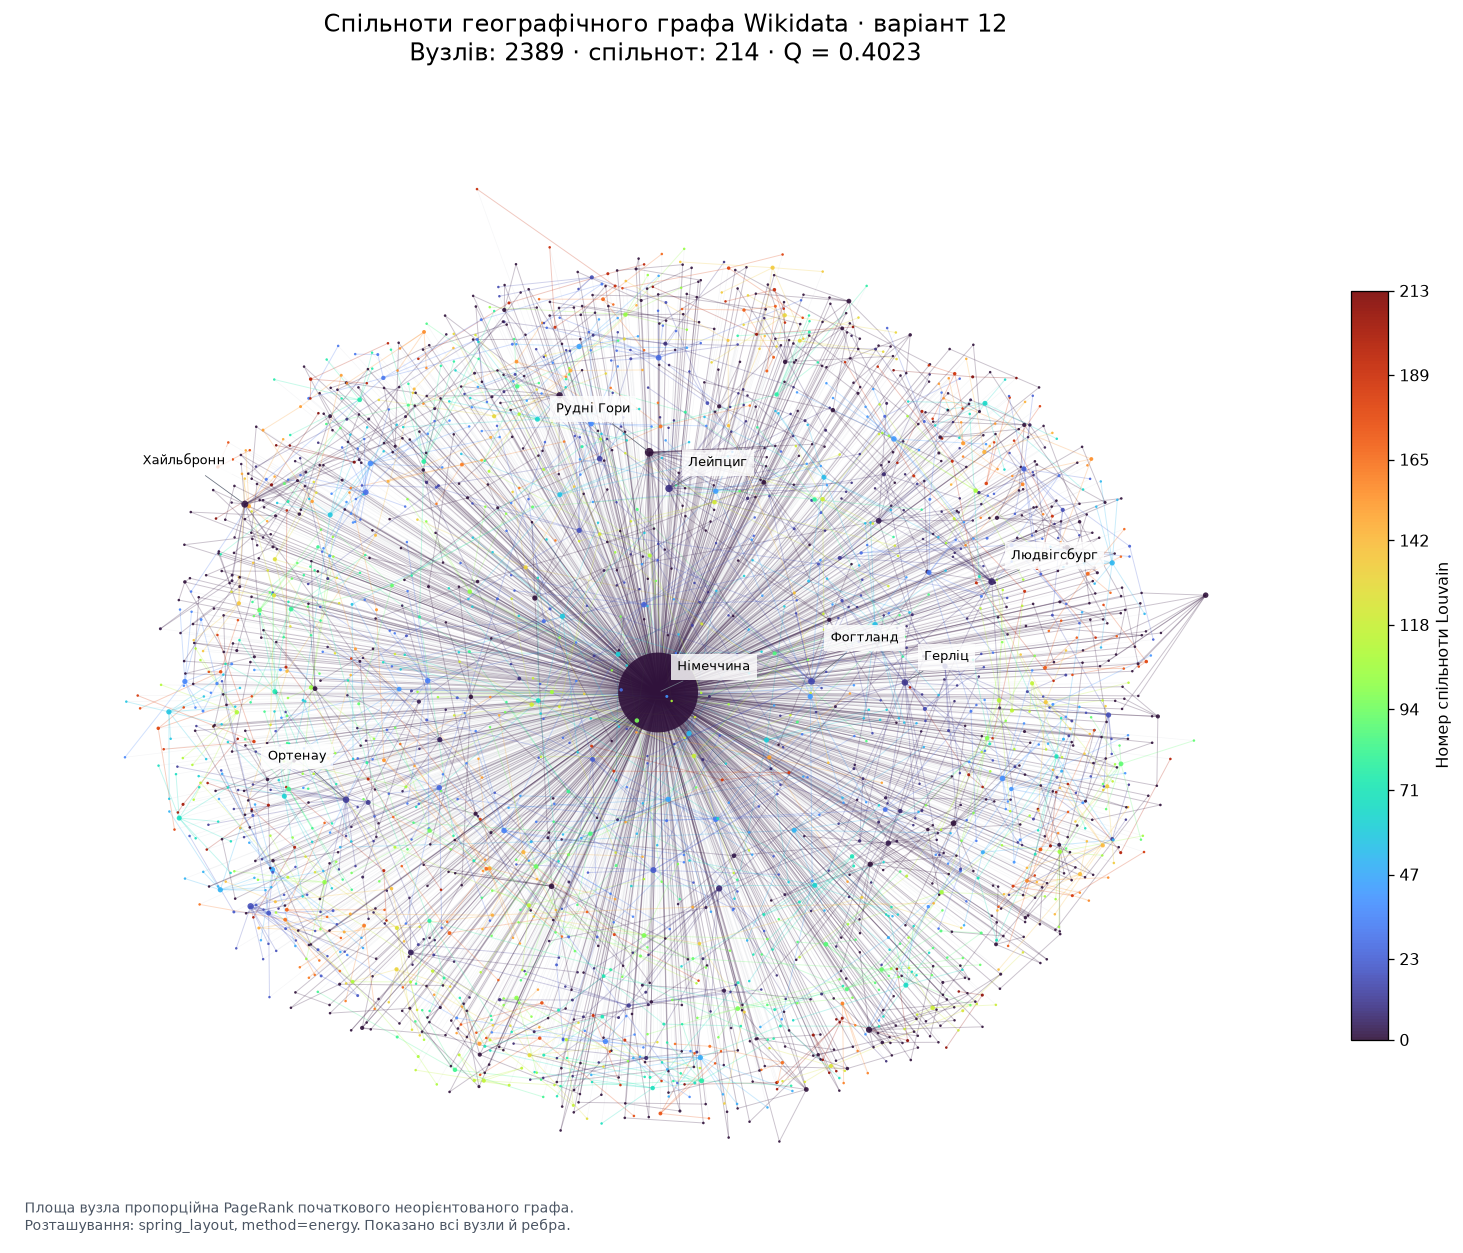

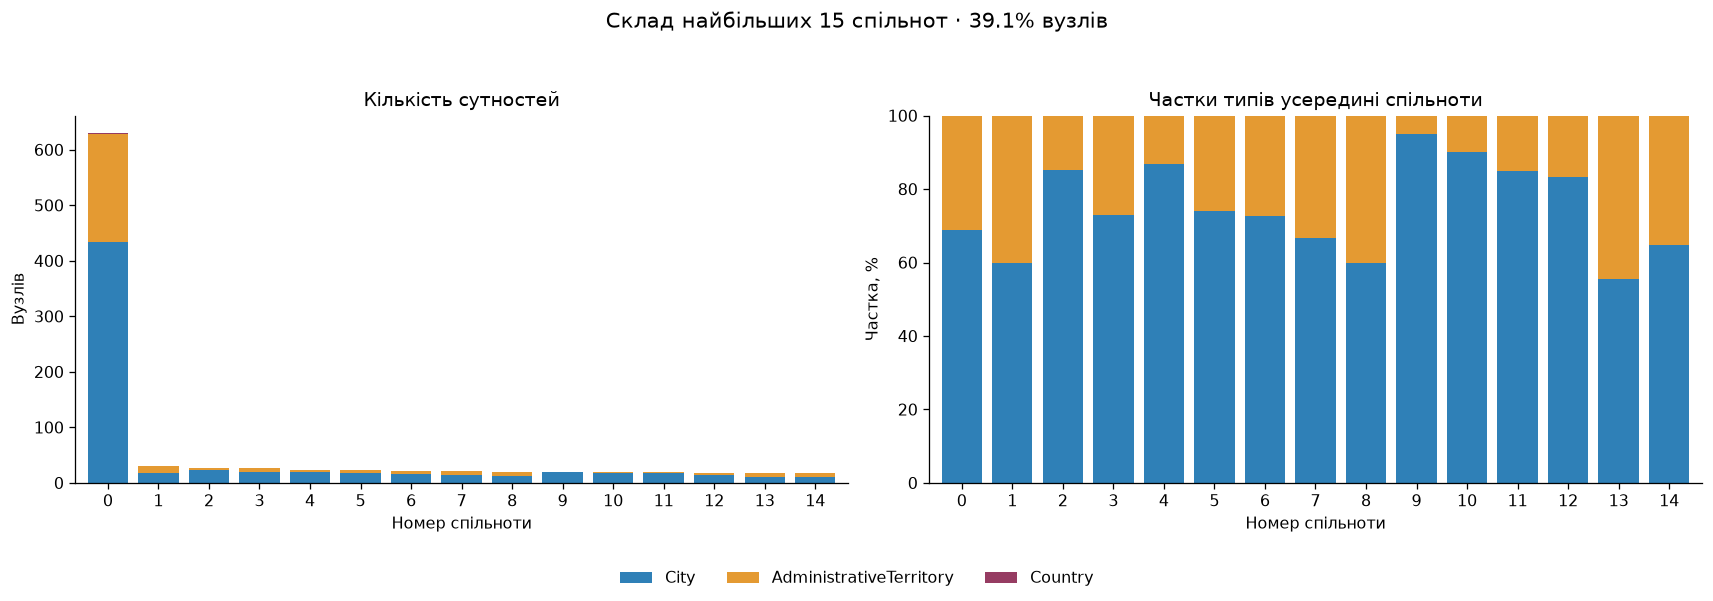

In [7]:
def plot_communities(
    result: AnalysisResult, config: AnalysisConfig = DEFAULT_CONFIG
) -> Figure:
    graph = result.undirected
    nodes = sorted(graph)
    positions = nx.spring_layout(
        graph, seed=config.seed, weight=None, iterations=90, method="energy"
    )
    ranks = result.scores.pagerank
    colors = [int(result.scores.at[node, "community"]) for node in nodes]
    sizes = [2500 * float(ranks[node]) / float(ranks.max()) for node in nodes]
    figure, axes = plt.subplots(figsize=(14, 11))
    community_of = result.scores.community.to_dict()
    inside = [(u, v) for u, v in graph.edges() if community_of[u] == community_of[v]]
    outside = [(u, v) for u, v in graph.edges() if community_of[u] != community_of[v]]
    nx.draw_networkx_edges(
        graph,
        positions,
        edgelist=outside,
        ax=axes,
        alpha=0.06,
        width=0.45,
        edge_color="#6B7280",
    )
    nx.draw_networkx_edges(
        graph,
        positions,
        edgelist=inside,
        ax=axes,
        alpha=0.25,
        width=0.6,
        edge_color=[
            matplotlib.colormaps["turbo"](
                community_of[u] / max(1, len(result.communities) - 1)
            )
            for u, _ in inside
        ],
    )
    artists = nx.draw_networkx_nodes(
        graph,
        positions,
        ax=axes,
        nodelist=nodes,
        node_size=sizes,
        node_color=colors,
        cmap=matplotlib.colormaps["turbo"],
        vmin=0,
        vmax=max(1, len(result.communities) - 1),
        linewidths=0,
        alpha=0.9,
    )
    leaders = sorted(nodes, key=lambda node: (-ranks[node], node))[:8]
    for index, node in enumerate(leaders):
        x, y = positions[node]
        label = textwrap.fill(graph.nodes[node]["label"], 24)
        axes.annotate(
            label,
            (x, y),
            xytext=(12 if x >= 0 else -12, 14 + 11 * (index % 2)),
            textcoords="offset points",
            ha="left" if x >= 0 else "right",
            fontsize=8,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.82},
            arrowprops={"arrowstyle": "-", "color": "#6B7280", "lw": 0.5},
        )
    colorbar = figure.colorbar(artists, ax=axes, shrink=0.65, pad=0.02)
    colorbar.set_label("Номер спільноти Louvain")
    colorbar.set_ticks(
        np.unique(
            np.linspace(
                0,
                len(result.communities) - 1,
                min(10, len(result.communities)),
                dtype=int,
            )
        )
    )
    axes.set_title(
        f"Спільноти географічного графа Wikidata · варіант 12\n"
        f"Вузлів: {len(graph)} · спільнот: {len(result.communities)} · "
        f"Q = {result.metrics['communities']['modularity']:.4f}",
        fontsize=15,
        pad=18,
    )
    axes.text(
        0.01,
        0.01,
        "Площа вузла пропорційна PageRank початкового неорієнтованого графа.\n"
        "Розташування: spring_layout, method=energy. Показано всі вузли й ребра.",
        transform=axes.transAxes,
        fontsize=9,
        color="#4B5563",
    )
    axes.axis("off")
    figure.tight_layout()
    return figure


def plot_composition(result: AnalysisResult) -> Figure:
    composition = result.tables["community_composition"]
    wide = (
        composition.pivot(index="community", columns="type", values="nodes")
        .fillna(0)
        .head(15)
    )
    wide = wide.reindex(
        columns=["City", "AdministrativeTerritory", "Country"], fill_value=0
    )
    proportions = wide.div(wide.sum(axis=1), axis=0) * 100
    figure, axes = plt.subplots(1, 2, figsize=(15, 5.2))
    for axis, data, title, ylabel in (
        (axes[0], wide, "Кількість сутностей", "Вузлів"),
        (axes[1], proportions, "Частки типів усередині спільноти", "Частка, %"),
    ):
        data.plot.bar(
            stacked=True,
            ax=axis,
            color=["#2F80B7", "#E49A32", "#963C62"],
            width=0.8,
            legend=False,
        )
        axis.set(title=title, xlabel="Номер спільноти", ylabel=ylabel)
        axis.tick_params(axis="x", rotation=0)
    coverage = wide.to_numpy().sum() / len(result.graph)
    figure.suptitle(
        f"Склад найбільших {len(wide)} спільнот · {coverage:.1%} вузлів",
        fontsize=13,
    )
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, ncol=3, loc="lower center", frameon=False)
    figure.tight_layout(rect=(0, 0.08, 1, 0.94))
    return figure

figure = plot_communities(result, config)
figure.savefig(OUT / "communities.png", dpi=180, bbox_inches="tight")
plt.show()
figure = plot_composition(result)
figure.savefig(OUT / "community_composition.png", dpi=180, bbox_inches="tight")
plt.show()

In [8]:
main_hub = result.metrics["semantic"]["main_hub"]
display(Markdown(
    f"**Висновок до завдання 2.** Центральний хаб — "
    f"{G_multidigraph.nodes[main_hub]['label']} ({main_hub}), PageRank="
    f"{result.scores.at[main_hub, 'pagerank']:.6f}. "
    "Візуалізація показує адміністративні групи навколо спільного країнового ядра. "
    "Кольори позначають структурні спільноти, тоді як друга діаграма показує типи "
    "сутностей. Значення PageRank і назви типів у цих двох поданнях не змішуються."))

**Висновок до завдання 2.** Центральний хаб — Німеччина (Q183), PageRank=0.244744. Візуалізація показує адміністративні групи навколо спільного країнового ядра. Кольори позначають структурні спільноти, тоді як друга діаграма показує типи сутностей. Значення PageRank і назви типів у цих двох поданнях не змішуються.

## Завдання 3 Степені та структурна стійкість

Степені та PageRank обчислено на G_undirected. Гістограма має логарифмічні
інтервали; частоти поділено на ширину інтервалу. Також показано точну PMF
і CCDF у координатах log-log. Наявність хабів сама по собі не доводить
степеневого закону чи безмасштабності.

П'ять вузлів для атаки впорядковано **один раз за початковим PageRank**.
Після видалень рейтинг не перераховується. У таблиці є початковий стан
і стан після кожного видалення. Ізольовані вузли, що виникли після атаки,
залишаються у графі та враховуються як окремі компоненти.

Порівняння — 500 незалежних випадкових наборів із п'яти різних вузлів,
вибраних рівноймовірно без повернення. Смуга на рисунку — емпіричні
2.5-й і 97.5-й перцентилі, а не довірчий інтервал оцінки середнього.

In [9]:
display(result.tables["initial_top5_pagerank"])
display(result.tables["targeted_attack"])
display(result.tables["random_attack_summary"])
display(result.tables["degree_distribution"])

,qid,label,type,degree,degree_centrality,pagerank,community
0,Q183,Німеччина,Country,2388,1.000000,0.244744,0
1,Q6339,Рудні Гори,AdministrativeTerritory,28,0.011725,0.002870,0
2,Q6308,Лейпциг,AdministrativeTerritory,20,0.008375,0.002071,9
3,Q7166,Хайльбронн,AdministrativeTerritory,19,0.007956,0.001897,1
4,Q8541,Людвігсбург,AdministrativeTerritory,18,0.007538,0.001829,5


,step,removed_qid,removed_label,removed_type,remaining_nodes,components,largest_component,largest_fraction_initial,largest_fraction_remaining,isolates,initial_pagerank
0,0,,,,2389,1,2389,1.000000,1.000000,0,0.000000
1,1,Q183,Німеччина,Country,2388,401,30,0.012558,0.012563,0,0.244744
2,2,Q6339,Рудні Гори,AdministrativeTerritory,2387,427,30,0.012558,0.012568,27,0.002870
3,3,Q6308,Лейпциг,AdministrativeTerritory,2386,445,30,0.012558,0.012573,46,0.002071
4,4,Q7166,Хайльбронн,AdministrativeTerritory,2385,461,27,0.011302,0.011321,52,0.001897
5,5,Q8541,Людвігсбург,AdministrativeTerritory,2384,476,27,0.011302,0.011326,63,0.001829


,step,components_mean,components_p025,components_p975,largest_mean,largest_p025,largest_p975
0,0,1.0,1.0,1.0,2389.0,2389.0,2389.0
1,1,1.0,1.0,1.0,2388.0,2388.0,2388.0
2,2,1.0,1.0,1.0,2387.0,2387.0,2387.0
3,3,1.0,1.0,1.0,2386.0,2386.0,2386.0
4,4,1.0,1.0,1.0,2385.0,2385.0,2385.0
5,5,1.0,1.0,1.0,2384.0,2384.0,2384.0


,degree,count,fraction,ccdf
0,2,1835,0.768104,1.000000
1,3,290,0.121390,0.231896
2,4,55,0.023022,0.110506
3,5,33,0.013813,0.087484
4,6,53,0.022185,0.073671
...,...,...,...,...
16,18,1,0.000419,0.002093
17,19,1,0.000419,0.001674
18,20,1,0.000419,0.001256
19,28,1,0.000419,0.000837


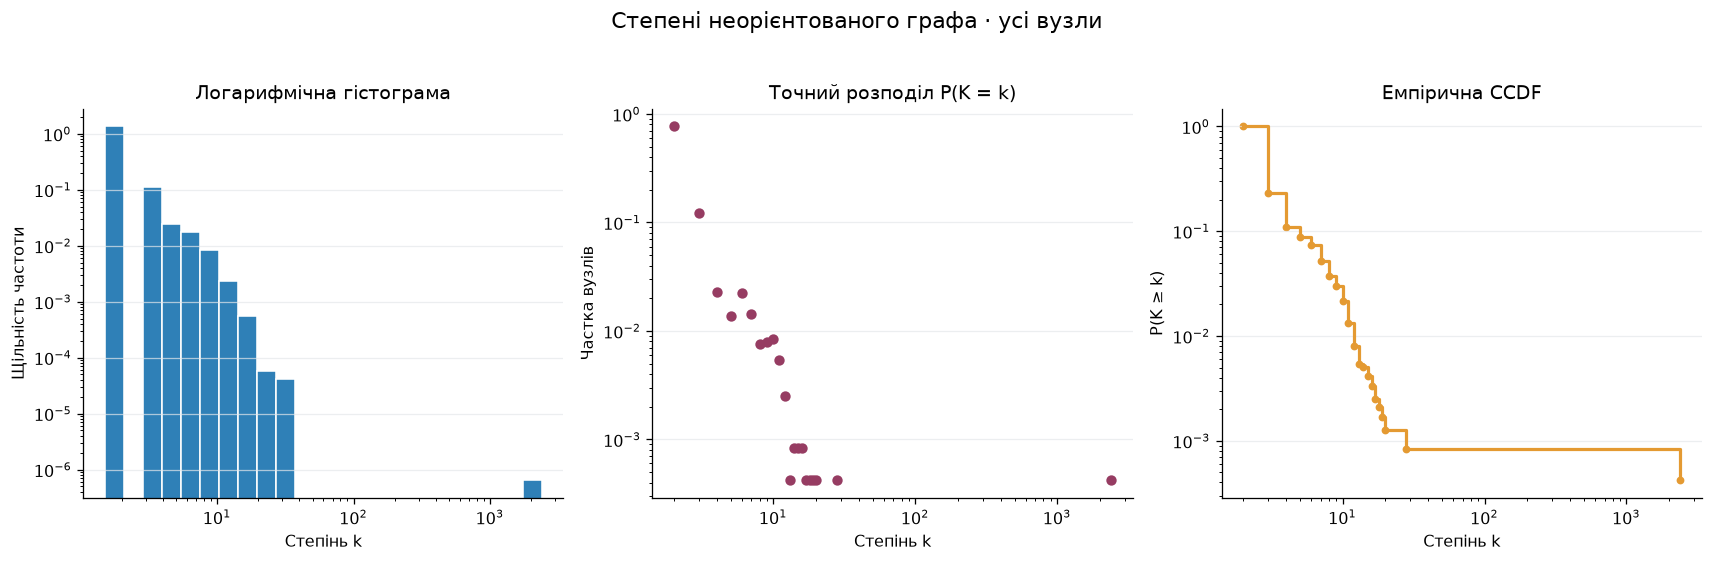

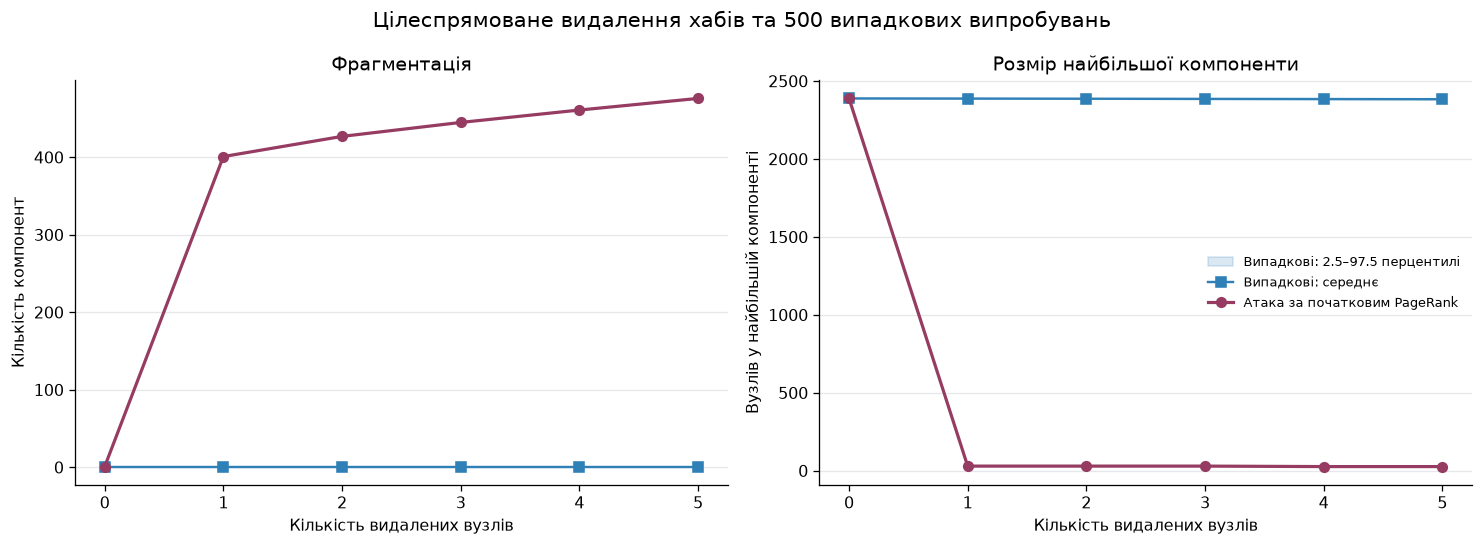

In [10]:
def plot_degree_distribution(result: AnalysisResult) -> Figure:
    data = result.tables["degree_distribution"]
    degrees = np.array([degree for _, degree in result.undirected.degree()])
    bins = np.geomspace(
        max(0.5, float(degrees.min()) - 0.5), float(degrees.max()) + 0.5, 24
    )
    counts, boundaries = np.histogram(degrees, bins=bins)
    widths = np.diff(boundaries)
    nonzero = counts > 0
    figure, axes = plt.subplots(1, 3, figsize=(15, 4.7))
    axes[0].bar(
        boundaries[:-1][nonzero],
        counts[nonzero] / (len(degrees) * widths[nonzero]),
        width=widths[nonzero],
        align="edge",
        color="#2F80B7",
        edgecolor="white",
    )
    axes[0].set(
        xscale="log",
        yscale="log",
        title="Логарифмічна гістограма",
        xlabel="Степінь k",
        ylabel="Щільність частоти",
    )
    axes[1].scatter(data.degree, data.fraction, color="#963C62", s=30)
    axes[1].set(
        xscale="log",
        yscale="log",
        title="Точний розподіл P(K = k)",
        xlabel="Степінь k",
        ylabel="Частка вузлів",
    )
    axes[2].step(data.degree, data.ccdf, where="post", color="#E49A32", linewidth=2)
    axes[2].scatter(data.degree, data.ccdf, color="#E49A32", s=15)
    axes[2].set(
        xscale="log",
        yscale="log",
        title="Емпірична CCDF",
        xlabel="Степінь k",
        ylabel="P(K ≥ k)",
    )
    for axis in axes:
        axis.grid(axis="y", color="#E5E7EB", alpha=0.7)
    figure.suptitle("Степені неорієнтованого графа · усі вузли", fontsize=14, y=1.03)
    figure.tight_layout()
    return figure


def plot_resilience(result: AnalysisResult) -> Figure:
    targeted = result.tables["targeted_attack"]
    random = result.tables["random_attack_summary"]
    figure, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for axis, column, prefix, ylabel in (
        (axes[0], "components", "components", "Кількість компонент"),
        (axes[1], "largest_component", "largest", "Вузлів у найбільшій компоненті"),
    ):
        axis.fill_between(
            random.step,
            random[f"{prefix}_p025"],
            random[f"{prefix}_p975"],
            color="#2F80B7",
            alpha=0.18,
            label="Випадкові: 2.5–97.5 перцентилі",
        )
        axis.plot(
            random.step,
            random[f"{prefix}_mean"],
            color="#2F80B7",
            marker="s",
            label="Випадкові: середнє",
        )
        axis.plot(
            targeted.step,
            targeted[column],
            color="#963C62",
            marker="o",
            linewidth=2,
            label="Атака за початковим PageRank",
        )
        axis.set(xlabel="Кількість видалених вузлів", ylabel=ylabel)
        axis.set_xticks(targeted.step)
        axis.grid(axis="y", color="#E5E7EB")
    axes[0].set_title("Фрагментація")
    axes[1].set_title("Розмір найбільшої компоненти")
    axes[1].legend(fontsize=8, frameon=False, loc="center right")
    figure.suptitle(
        "Цілеспрямоване видалення хабів та "
        f"{result.metrics['resilience']['random_trials']} випадкових випробувань",
        fontsize=13,
    )
    figure.tight_layout()
    return figure

figure = plot_degree_distribution(result)
figure.savefig(OUT / "degree_distribution.png", dpi=180, bbox_inches="tight")
plt.show()
figure = plot_resilience(result)
figure.savefig(OUT / "resilience.png", dpi=180, bbox_inches="tight")
plt.show()

In [11]:
attack = result.metrics["resilience"]
first_removal = result.tables["targeted_attack"].iloc[1]
display(Markdown(
    f"**Висновок до завдання 3.** Хаби наявні: степінь країнового ядра дорівнює "
    f"{G_undirected.degree(main_hub)} за середнього степеня "
    f"{2 * G_undirected.number_of_edges() / len(G_undirected):.3f}. "
    "Розподіл сильно неоднорідний; за цим log-log рисунком безмасштабність не підтверджується. "
    "Спільна країна й схема вибірки примусово створюють один надвеликий хаб. "
    f"Після першого видалення є {int(first_removal.components)} компонент, "
    f"найбільша містить {int(first_removal.largest_component)} вузлів. "
    f"Після п'яти видалень — {attack['targeted_final_components']} компонент "
    f"із найбільшою розміром {attack['targeted_final_largest']}. "
    f"Для випадкових видалень середній кінцевий розмір найбільшої компоненти — "
    f"{attack['random_final_largest_mean']:.1f}. "
    "Глобально критичним є тип Country. Адміністративні одиниці стають критичними "
    "для локальних груп після втрати країнового ядра. Аналіз стосується "
    "неорієнтованої структури та не оцінює збереження напрямлених RDF-зв'язків."))
display(Markdown(
    f"**Рідкісний випадок у випадковому контролі.** У цих "
    f"{config.random_trials} випробуваннях головний хаб вибрано "
    f"{attack['random_includes_main_hub_trials']} разів. Точна ймовірність його "
    f"потрапляння до одного набору з п'яти вузлів — 5/{len(G_undirected)} = "
    f"{attack['random_main_hub_hit_probability']:.4%}. Ймовірність не вибрати його "
    f"жодного разу за 500 випробувань — {attack['probability_no_main_hub_hit_in_trials']:.2%}. "
    "Тому нуль спостережених таких випадків не означає нульового ризику: "
    "за збереження універсального ядра решта вузлів гарантовано лишається зв'язною, "
    "а його видалення руйнує цей структурний механізм."))

**Висновок до завдання 3.** Хаби наявні: степінь країнового ядра дорівнює 2388 за середнього степеня 3.685. Розподіл сильно неоднорідний; за цим log-log рисунком безмасштабність не підтверджується. Спільна країна й схема вибірки примусово створюють один надвеликий хаб. Після першого видалення є 401 компонент, найбільша містить 30 вузлів. Після п'яти видалень — 476 компонент із найбільшою розміром 27. Для випадкових видалень середній кінцевий розмір найбільшої компоненти — 2384.0. Глобально критичним є тип Country. Адміністративні одиниці стають критичними для локальних груп після втрати країнового ядра. Аналіз стосується неорієнтованої структури та не оцінює збереження напрямлених RDF-зв'язків.

**Рідкісний випадок у випадковому контролі.** У цих 500 випробуваннях головний хаб вибрано 0 разів. Точна ймовірність його потрапляння до одного набору з п'яти вузлів — 5/2389 = 0.2093%. Ймовірність не вибрати його жодного разу за 500 випробувань — 35.08%. Тому нуль спостережених таких випадків не означає нульового ризику: за збереження універсального ядра решта вузлів гарантовано лишається зв'язною, а його видалення руйнує цей структурний механізм.

## Завдання 4 Семантичні шляхи та его графи

Дві сутності обираються серед міст із різними адміністративними околицями.
Шлях знаходиться функцією shortest_path на неорієнтованій проєкції.
Для кожного кроку предикат і початковий напрямок відновлюються з
G_multidigraph; проходження проти RDF-напрямку позначається лівою стрілкою.

Основний его-граф має радіус 2 навколо головного хаба. Додатково виділено
менший его-граф радіуса 1 навколо провідної адміністративної одиниці.

In [12]:
print(result.details["semantic"]["shortest_path_text"])
display(result.tables["semantic_path_steps"])
display(result.tables["ego_graphs"])
print("Чи існує напрямлений шлях між цими містами:", result.metrics["semantic"]["directed_reachable"])

An der Schmücke (Q59775092) —P17→ Німеччина (Q183) ←P17— Aue-Bad Schlema (Q59564401)


,step,traversal_from,traversal_to,rdf_source,rdf_source_label,rdf_target,rdf_target_label,property,relation,property_uri,edge_key,traversal_direction
0,1,Q59775092,Q183,Q59775092,An der Schmücke,Q183,Німеччина,P17,CityCountry,http://www.wikidata.org/prop/direct/P17,P17,along
1,2,Q183,Q59564401,Q59564401,Aue-Bad Schlema,Q183,Німеччина,P17,CityCountry,http://www.wikidata.org/prop/direct/P17,P17,against


,role,center,label,radius,nodes,edges,node_fraction
0,main_hub,Q183,Німеччина,2,2389,4402,1.000000
1,additional_local_admin,Q6339,Рудні Гори,1,29,55,0.012139


Чи існує напрямлений шлях між цими містами: False


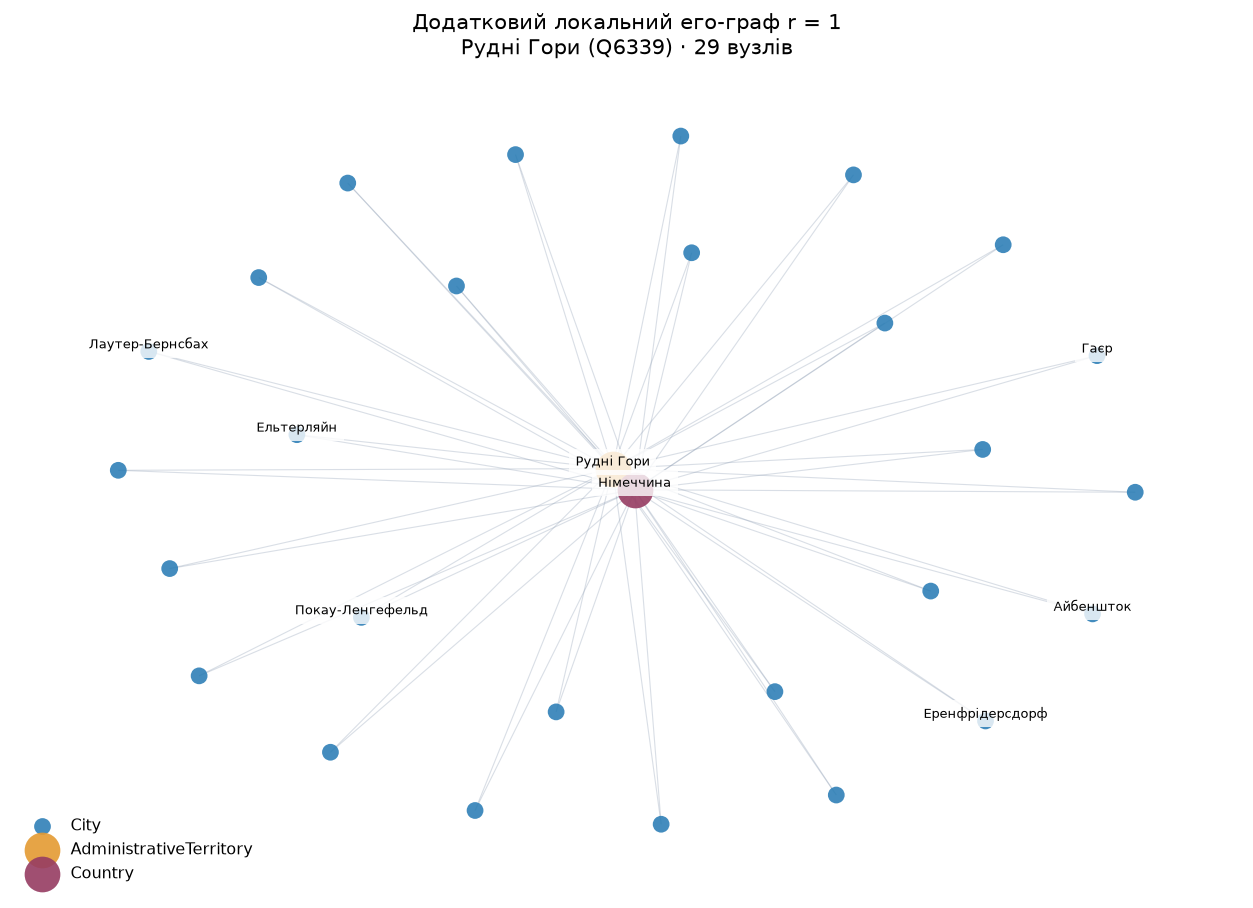

In [13]:
def plot_local_ego(
    result: AnalysisResult, config: AnalysisConfig = DEFAULT_CONFIG
) -> Figure:
    graph = result.local_ego
    positions = nx.spring_layout(
        graph, seed=config.seed, weight=None, iterations=100, method="force"
    )
    colors = {
        "City": "#2F80B7",
        "AdministrativeTerritory": "#E49A32",
        "Country": "#963C62",
    }
    figure, axes = plt.subplots(figsize=(11, 8))
    nx.draw_networkx_edges(
        graph, positions, ax=axes, edge_color="#94A3B8", alpha=0.35, width=0.7
    )
    for kind, color in colors.items():
        nodes = sorted(node for node in graph if graph.nodes[node]["type"] == kind)
        nx.draw_networkx_nodes(
            graph,
            positions,
            ax=axes,
            nodelist=nodes,
            node_color=color,
            node_size=[80 + 15 * graph.degree(node) for node in nodes],
            label=kind,
            alpha=0.9,
            linewidths=0,
        )
    leaders = sorted(graph, key=lambda node: (-graph.degree(node), node))[:8]
    labels = {node: textwrap.fill(graph.nodes[node]["label"], 24) for node in leaders}
    nx.draw_networkx_labels(
        graph,
        positions,
        labels=labels,
        font_size=8,
        ax=axes,
        verticalalignment="bottom",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8},
    )
    center = result.metrics["semantic"]["local_hub"]
    axes.set_title(
        f"Додатковий локальний его-граф r = 1\n"
        f"{result.graph.nodes[center]['label']} ({center}) · {len(graph)} вузлів",
        fontsize=13,
    )
    axes.legend(frameon=False, loc="lower left")
    axes.axis("off")
    figure.tight_layout()
    return figure

figure = plot_local_ego(result, config)
figure.savefig(OUT / "ego_local.png", dpi=180, bbox_inches="tight")
plt.show()

In [14]:
semantic = result.metrics["semantic"]
display(Markdown(
    f"**Висновок до завдання 4.** Найкоротший шлях має "
    f"{semantic['shortest_path_length']} ребра, що дорівнює діаметру "
    f"{semantic['undirected_diameter']}. У цій мережі відстаней понад два ребра немає: "
    "усі сутності суміжні з країною. Шлях через Country означає спільну країнову "
    "належність, а не прямий адміністративний зв'язок між містами. "
    f"Основний его-граф r=2 охоплює {semantic['main_ego_nodes']} вузлів "
    f"({semantic['main_ego_fraction']:.0%} мережі) та збігається з усім графом. "
    f"Додатковий локальний его-граф містить {semantic['local_ego_nodes']} вузлів "
    "і показує адміністративну околицю у меншому масштабі."))

**Висновок до завдання 4.** Найкоротший шлях має 2 ребра, що дорівнює діаметру 2. У цій мережі відстаней понад два ребра немає: усі сутності суміжні з країною. Шлях через Country означає спільну країнову належність, а не прямий адміністративний зв'язок між містами. Основний его-граф r=2 охоплює 2389 вузлів (100% мережі) та збігається з усім графом. Додатковий локальний его-граф містить 29 вузлів і показує адміністративну околицю у меншому масштабі.

## Завдання 5 Передбачення зв'язку

Цільове відношення — City → P131 → AdministrativeTerritory. Обираються
різнотипні пари без прямого ребра в обох напрямках. Початкові зв'язки не
приховуються: відсутні пари цього типу вже існують у знімку.

Для кожної обраної пари **точно перелічуються всі прості шляхи з 2 або 3
ребер**. Довші шляхи не враховуються. Шаблон
City → P131 → Admin ← P131 ← City → P131 → Admin оцінює спільне
адміністративне оточення. Маршрути через Country виділяються як загальний
контекст. Кандидати впорядковуються за кількістю P131-шляхів, а при рівності —
за коефіцієнтом Жаккара між містами їхніх околиць. Це структурні свідчення,
а не автоматично встановлені факти Wikidata.

Додано порівняльну пару без специфічних P131-шляхів; вона не позначається
хибним фактом, оскільки відсутність ребра в підграфі не задає істинності
факту у світі.

In [15]:
candidates = result.tables["link_candidates"]
display(candidates)
selected = candidates.iloc[0]
print("Гіпотеза:", selected.city_label, "—P131→", selected.admin_label)
patterns = result.tables["link_path_patterns"]
display(patterns[(patterns.city == selected.city) & (patterns.candidate_admin == selected.candidate_admin)])
examples = result.tables["link_path_examples"]
display(examples[(examples.city == selected.city) & (examples.candidate_admin == selected.candidate_admin)])

,city,city_label,candidate_admin,admin_label,role,direct_edge_present,shortest_length,paths_length2,paths_length3,all_paths_up_to3,specific_p131_paths,supporting_cities,jaccard_peer_cities
0,Q253696,Прюм,Q15852582,Südeifel,candidate,False,2,1,7,8,3,3,0.750
1,Q258974,Бітбург,Q15852582,Südeifel,candidate,False,2,1,7,8,3,3,0.750
2,Q50872,Меккерн,Q1687656,Jerichow District,candidate,False,2,1,7,8,3,3,0.750
3,Q50880,Гоммерн,Q1687656,Jerichow District,candidate,False,2,1,7,8,3,3,0.750
4,Q14815,Вайсенфельс,Q478740,Unstruttal,candidate,False,2,1,7,8,3,3,0.375
5,Q15986,Наумбург,Q478740,Unstruttal,candidate,False,2,1,7,8,3,3,0.375
6,Q16087,Цайц,Q478740,Unstruttal,candidate,False,2,1,7,8,3,3,0.375
7,Q517174,Лютцен,Q478740,Unstruttal,candidate,False,2,1,7,8,3,3,0.375
8,Q253696,Прюм,Q10401,Ліндау,comparison_without_specific_paths,False,2,1,3,4,0,0,0.000


Гіпотеза: Прюм —P131→ Südeifel


,city,candidate_admin,length,typed_path,count,specific_p131_evidence
0,Q253696,Q15852582,2,City -P17-> Country <-P17- AdministrativeTerritory,1,False
1,Q253696,Q15852582,3,City -P131-> AdministrativeTerritory -P17-> Country <-P17- Ad...,1,False
2,Q253696,Q15852582,3,City -P131-> AdministrativeTerritory <-P131- City -P131-> Adm...,3,True
3,Q253696,Q15852582,3,City -P17-> Country <-P17- City -P131-> AdministrativeTerritory,3,False


,city,candidate_admin,length,qids,semantic_path
0,Q253696,Q15852582,3,Q253696 > Q8580 > Q543370 > Q15852582,Прюм (Q253696) —P131→ Бітбург-Прюм (Q8580) ←P131— Ноєрбург (Q...
1,Q253696,Q15852582,3,Q253696 > Q8580 > Q544146 > Q15852582,Прюм (Q253696) —P131→ Бітбург-Прюм (Q8580) ←P131— Боллендорф ...
2,Q253696,Q15852582,3,Q253696 > Q8580 > Q553503 > Q15852582,Прюм (Q253696) —P131→ Бітбург-Прюм (Q8580) ←P131— Ехтернахерб...
3,Q253696,Q15852582,2,Q253696 > Q183 > Q15852582,Прюм (Q253696) —P17→ Німеччина (Q183) ←P17— Südeifel (Q15852582)
4,Q253696,Q15852582,3,Q253696 > Q183 > Q543370 > Q15852582,Прюм (Q253696) —P17→ Німеччина (Q183) ←P17— Ноєрбург (Q543370...


In [16]:
link = result.metrics["link_prediction"]
display(Markdown(
    f"**Висновок до завдання 5.** Для пари **{selected.city_label} → "
    f"{selected.admin_label}** прямий P131 відсутній. Знайдено "
    f"{link['selected_all_paths_up_to3']} простих шляхів довжини 2–3, з них "
    f"{link['selected_specific_paths']} проходять лише через типізовані P131. "
    "Пара має спільне адміністративне оточення, однак країнові шляхи та "
    "спільні сусіди не встановлюють включення одного об'єкта в конкретну "
    "адміністративну територію. Додавання такого P131 без перевірки зовнішніх "
    "джерел і часових кваліфікаторів недостатньо обґрунтоване. "
    "Результат є ранжуванням гіпотез для перевірки; відсутність триплета "
    "в досліджуваному графі не доводить відсутності факту в реальному світі."))

**Висновок до завдання 5.** Для пари **Прюм → Südeifel** прямий P131 відсутній. Знайдено 8 простих шляхів довжини 2–3, з них 3 проходять лише через типізовані P131. Пара має спільне адміністративне оточення, однак країнові шляхи та спільні сусіди не встановлюють включення одного об'єкта в конкретну адміністративну територію. Додавання такого P131 без перевірки зовнішніх джерел і часових кваліфікаторів недостатньо обґрунтоване. Результат є ранжуванням гіпотез для перевірки; відсутність триплета в досліджуваному графі не доводить відсутності факту в реальному світі.

## Підсумок та збереження результатів

Виконано всі п'ять завдань. Найважливіша особливість мережі — універсальне
країнове ядро. Воно пояснює короткі шляхи, видимість локальних
адміністративних груп, відсутність мостів і різку фрагментацію після
видалення одного вузла. Висновки стосуються цього способу вибірки та
зафіксованого підграфа, а не всієї географії Wikidata.

У CSV збережено склад і хаби всіх спільнот, усі міжкластерні ребра,
усі випадкові випробування та структурні свідчення кандидатних зв'язків.
GraphML містить вихідний напрямлений граф із номерами спільнот та
PageRank проєкції. Его-графи зберігаються окремо. Вхідні дані не змінюються.

In [17]:
def export_results(
    result: AnalysisResult,
    output: Path,
    config: AnalysisConfig = DEFAULT_CONFIG,
    *,
    plots: bool = True,
) -> None:
    output.mkdir(parents=True, exist_ok=True)
    result.scores.to_csv(
        output / "node_scores.csv", encoding="utf-8-sig", lineterminator="\n"
    )
    for name, table in result.tables.items():
        table.to_csv(
            output / f"{name}.csv",
            index=False,
            encoding="utf-8-sig",
            lineterminator="\n",
        )
    write_json(
        output / "metrics.json",
        {
            **result.metrics,
            "config": asdict(config),
            "versions": library_versions(),
            "input_sha256": INPUT_SHA256,
        },
    )
    write_json(output / "semantic_details.json", result.details)
    nx.write_graphml(result.main_ego, output / "ego_main_radius2.graphml")
    nx.write_graphml(result.local_ego, output / "ego_local_admin_radius1.graphml")
    graph = result.graph.copy()
    for node in graph:
        graph.nodes[node]["community"] = int(result.scores.at[node, "community"])
        graph.nodes[node]["undirected_pagerank"] = float(
            result.scores.at[node, "pagerank"]
        )
    nx.write_graphml(graph, output / "variant12_community_graph.graphml")
    if plots:
        for filename, draw in (
            ("communities.png", plot_communities),
            ("community_composition.png", plot_composition),
            ("degree_distribution.png", plot_degree_distribution),
            ("resilience.png", plot_resilience),
            ("ego_local.png", plot_local_ego),
        ):
            figure = (
                draw(result, config)
                if draw in (plot_communities, plot_local_ego)
                else draw(result)
            )
            figure.savefig(output / filename, dpi=180, bbox_inches="tight")
            plt.close(figure)
    write_json(
        output / "sha256.json",
        {
            file.name: hashlib.sha256(file.read_bytes()).hexdigest()
            for file in sorted(output.iterdir())
            if file.is_file() and file.name != "sha256.json"
        },
    )

export_results(result, OUT, config, plots=False)
assert len(set().union(*result.communities)) == len(G_undirected)
assert sum(map(len, result.communities)) == len(G_undirected)
assert math.isclose(result.scores.pagerank.sum(), 1.0, abs_tol=1e-9)
assert result.tables["targeted_attack"].step.tolist() == list(range(6))
assert len(result.tables["random_attack_trials"]) == config.random_trials * 6
assert not result.tables["link_candidates"].direct_edge_present.any()
assert hashlib.sha256(payload).hexdigest() == INPUT_SHA256
restored = nx.read_graphml(OUT / "variant12_community_graph.graphml", force_multigraph=True)
assert set(restored) == set(G_multidigraph)
assert {(u, v, key) for u, v, key in restored.edges(keys=True)} == set(G_multidigraph.edges(keys=True))
assert set(result.main_ego) == set(G_undirected)
print("Усі перевірки виконано. Вхідний граф збережено без змін.")
for file in sorted(OUT.iterdir()):
    if file.is_file():
        print(file.name, f"{file.stat().st_size:,} байтів")

Усі перевірки виконано. Вхідний граф збережено без змін.
communities.png 3,508,220 байтів
community_admin_groups.csv 15,910 байтів
community_composition.csv 14,242 байтів
community_composition.png 75,014 байтів
community_hubs.csv 43,568 байтів
community_summary.csv 27,531 байтів
degree_distribution.csv 1,014 байтів
degree_distribution.png 75,633 байтів
ego_graphs.csv 181 байтів
ego_local.png 272,295 байтів
ego_local_admin_radius1.graphml 9,176 байтів
ego_main_radius2.graphml 698,073 байтів
graph_bridges.csv 17 байтів
initial_top5_pagerank.csv 515 байтів
intercommunity_edges.csv 110,272 байтів
intercommunity_pairs.csv 1,697 байтів
link_candidates.csv 897 байтів
link_path_examples.csv 7,970 байтів
link_path_patterns.csv 3,412 байтів
metrics.json 2,265 байтів
multiple_admin_cities.csv 19,796 байтів
node_scores.csv 206,314 байтів
random_attack_summary.csv 305 байтів
random_attack_trials.csv 215,456 байтів
resilience.png 97,753 байтів
semantic_details.json 572 байтів
semantic_path_steps.csv

## Джерела

1. Умова «Практичне заняття № 8. Поглиблений структурний, кластерний та семантичний аналіз графів знань Wikidata».
2. Знімок графа практичної 7. Первинне джерело — Wikidata через QLever; час отримання та походження записані в атрибутах графа. [Ліцензія даних Wikidata CC0](https://www.wikidata.org/wiki/Wikidata:Licensing).
3. [NetworkX Louvain](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.community.louvain.louvain_communities.html), [Modularity](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.community.quality.modularity.html).
4. [Spring layout](https://networkx.org/documentation/stable/auto_examples/drawing/plot_spring_layout.html), [PageRank](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html).
5. [Simple paths](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.simple_paths.all_simple_paths.html), [Ego graph](https://networkx.org/documentation/stable/reference/generated/networkx.generators.ego.ego_graph.html).